# C23 — Laboratório de Inteligência Artificial
## Aula 5: MLP — Multilayer Perceptron

**Objetivo da aula:** compreender e implementar uma rede neural do tipo *Multilayer Perceptron* (MLP), relacionando sua arquitetura, funções de ativação e treinamento com o desempenho obtido em um problema de classificação.

Nesta aula, construiremos uma MLP para classificar tumores a partir de atributos numéricos de exames. O foco não é apenas obter uma boa métrica: é entenderntender como os dados são preparados, como a rede aprende e quais decisões influenciam os resultados.

## 1. Conceitos Fundamentais

### 1.1. O que é uma rede neural artificial?

Uma rede neural artificial é um modelo de aprendizado de máquina formado por neurônios artificiais interconectados e organizados em camadas. Ela aprende, a partir de exemplos, uma função que relaciona atributos de entrada às saídas desejadas.

Redes neurais podem ser usadas em tarefas de **classificação** e **regressão**, entre outras. O MLP é uma arquitetura de rede neural que possui uma camada de entrada, uma ou mais camadas ocultas e uma camada de saída.

### 1.2. Como funciona um neurônio artificial?

Cada neurônio recebe valores de entrada, multiplica-os por pesos, soma os resultados com um termo de bias e aplica uma função de ativação:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

$$
a = f(z)
$$

- **Atributos (x):** valores fornecidos ao neurônio.
- **Pesos sinápticos (w):** definem a contribuição de cada entrada.
- **Bias (b):** permite deslocar a resposta do neurônio.
- **Função de ativação (f):** introduz não linearidade e transforma a soma ponderada.

O neurônio artificial é uma simplificação matemática inspirada em alguns aspectos do neurônio biológico. Ele não reproduz literalmente o funcionamento do cérebro.

### 1.3. Camadas de uma MLP

- **Camada de entrada:** recebe os atributos do problema. Em geral, há uma entrada para cada atributo.
- **Camadas ocultas:** combinam as informações recebidas e aprendem representações úteis para a tarefa.
- **Camada de saída:** produz a predição. Sua dimensão e ativação dependem do problema.

A quantidade de camadas e neurônios é chamada de **arquitetura** da rede. Uma arquitetura maior pode representar relações mais complexas, mas também aumenta o custo computacional e o risco de sobreajuste.

### 1.4. Funções de ativação

Algumas funções comuns são:

- **ReLU:** \(f(z)=\max(0,z)\). É muito utilizada em camadas ocultas.
- **Sigmoide:** transforma valores em saídas entre 0 e 1; pode ser usada em saídas binárias.
- **Softmax:** transforma os valores de saída em uma distribuição de probabilidades entre classes, em configurações multiclasse.
- **Linear:** comum na camada de saída de redes destinadas à regressão.

A escolha da ativação deve ser coerente com a tarefa. Nesta prática, usaremos a implementação `MLPClassifier` do scikit-learn, que configura a saída e a função de perda de acordo com o problema de classificação.

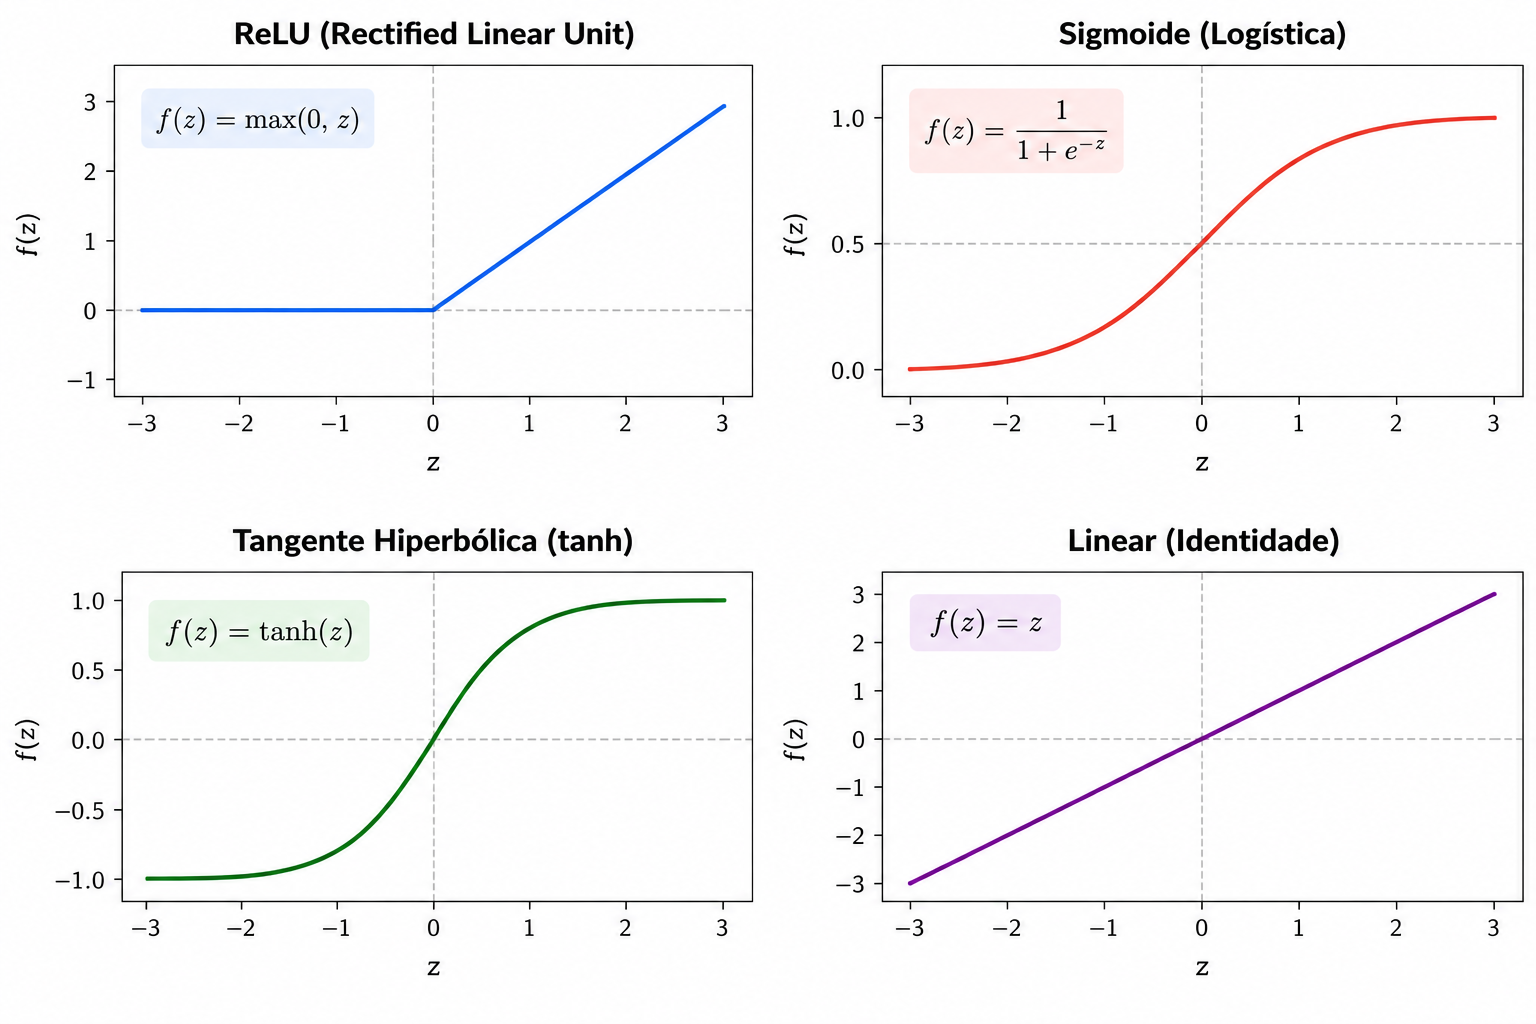

### 1.5. Como a rede aprende?

O treinamento ajusta os pesos e os bias para reduzir a diferença entre as predições e os rótulos conhecidos. Em uma visão simplificada, o ciclo é:

1. **Propagação direta (*forward pass*):** os dados atravessam a rede e geram uma predição.
2. **Cálculo do erro:** uma função de perda mede a discrepância entre a predição e o valor esperado.
3. **Retropropagação (*backpropagation*):** a regra da cadeia é usada para calcular como os pesos contribuem para o erro.
4. **Atualização dos parâmetros:** um algoritmo de otimização modifica os pesos para tentar reduzir a perda.

Esse processo se repete durante o treinamento. Uma **época** corresponde a uma passagem de treinamento pelo conjunto de exemplos, embora a forma exata de processamento dependa do algoritmo utilizado.


**Referências**

- Material teórico da disciplin.
- GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. *Deep Learning*. MIT Press, 2016.
- SCIKIT-LEARN. [Neural network models — Supervised learning](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).
- SCIKIT-LEARN. [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).


# 2. Prática Guiada

Nesta etapa, vamos treinar uma MLP para classificar tumores como **benignos** ou **malignos**, usando atributos numéricos extraídos de imagens de exames. Utilizaremos a base *Breast Cancer Wisconsin Diagnostic*, disponibilizada pelo scikit-learn.

Execute as células na ordem. Antes de avançar, observe o que cada etapa faz e por que ela é necessária. Ao final, responda às perguntas de reflexão com base nos resultados obtidos.

**Pipeline:** carregar os dados → explorar as classes → separar treino, validação e teste → padronizar os atributos → treinar a MLP → avaliar e interpretar os resultados.


### 2.1. Preparação do ambiente

Vamos importar as bibliotecas para manipulação de dados, construção do modelo e avaliação.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")


### 2.2. Carregamento e compreensão do conjunto de dados

A base contém medidas numéricas calculadas a partir de imagens de massas mamárias. A variável alvo identifica duas classes. Primeiro, vamos entender a dimensão dos dados, os atributos e os rótulos antes de treinar o modelo.

In [2]:
# Carregamos a base de dados fornecida pelo scikit-learn.
dados = load_breast_cancer(as_frame=True)

X = dados.data
y = dados.target

print(f"Número de amostras: {X.shape[0]}")
print(f"Número de atributos: {X.shape[1]}")
print(f"Classes codificadas: {np.unique(y)}")
print("\nNomes das classes:", dados.target_names)

display(X.head())


Número de amostras: 569
Número de atributos: 30
Classes codificadas: [0 1]

Nomes das classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 2.3. Análise inicial das classes

A distribuição das classes ajuda a interpretar as métricas. Neste conjunto, os rótulos numéricos correspondem aos nomes em `dados.target_names`; confira esse mapeamento antes de interpretar a matriz de confusão.

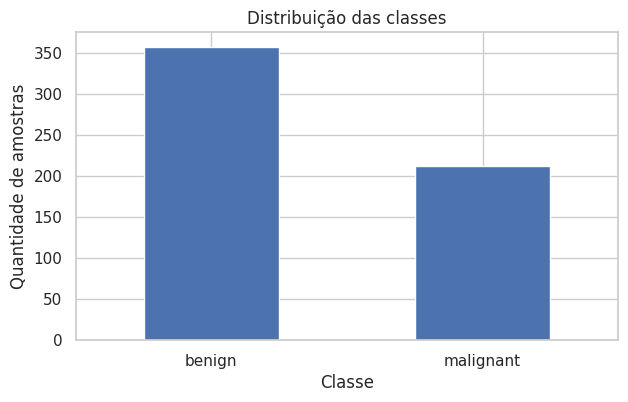

In [11]:
contagem = pd.Series(y).map(dict(enumerate(dados.target_names))).value_counts()

ax = contagem.plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribuição das classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de amostras")
plt.xticks(rotation=0)
plt.show()

### 2.4. Separação dos dados

Usaremos três subconjuntos:

- **Treino:** utilizado para ajustar os pesos da rede.
- **Validação:** utilizado para comparar configurações durante o desenvolvimento.
- **Teste:** reservado para uma avaliação final, depois de escolhida a configuração.

A opção `stratify` preserva aproximadamente a proporção das classes nas partições.

In [4]:
# Primeiro separamos o conjunto de teste.
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Depois separamos a validação a partir dos dados restantes.
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_treino_val, y_treino_val,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_treino_val
)

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)
print("Teste:", X_teste.shape, y_teste.shape)


Treino: (364, 30) (364,)
Validação: (91, 30) (91,)
Teste: (114, 30) (114,)


### 2.5. Por que padronizar os atributos?

Os atributos podem ter escalas muito diferentes. A padronização transforma cada atributo para uma escala baseada na média e no desvio padrão calculados no conjunto de treino. Isso pode facilitar a otimização da rede.

Vamos usar um `Pipeline` para garantir que o `StandardScaler` seja ajustado apenas com os dados de treino. Assim, evitamos que informações da validação ou do teste influenciem o pré-processamento.

In [12]:
# Observe as escalas de alguns atributos antes da padronização.
display(X_treino.describe().loc[["mean", "std", "min", "max"]].iloc[:, :6].round(2))

# Criamos uma MLP inicial para classificação binária.
modelo_mlp = Pipeline([
    ("padronizacao", StandardScaler()),  # Padroniza os atributos usando média e desvio padrão do treino.
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),  # Define duas camadas ocultas, com 32 e 16 neurônios.
        activation="relu",  # Define a função de ativação ReLU para as camadas ocultas.
        solver="adam",  # Define o algoritmo de otimização usado para ajustar os pesos.
        alpha=0.001,  # Controla a regularização L2 para ajudar a reduzir o sobreajuste.
        learning_rate_init=0.001,  # Define a taxa de aprendizado inicial das atualizações dos pesos.
        max_iter=500,  # Define o número máximo de iterações de treinamento.
        early_stopping=True,  # Interrompe o treino antecipadamente se a validação interna parar de melhorar.
        validation_fraction=0.15,  # Reserva 15% do conjunto de treino para validação interna.
        n_iter_no_change=20,  # Define quantas iterações sem melhora são toleradas antes de parar.
        random_state=RANDOM_STATE  # Fixa a semente aleatória para tornar os resultados mais reproduzíveis.
    ))
])

# Treinamos a rede com os dados de treinamento.
modelo_mlp.fit(X_treino, y_treino)

print("Treinamento concluído.")
print("Número de iterações:", modelo_mlp.named_steps["mlp"].n_iter_)
print(
    "Atingiu o limite máximo de iterações?",
    modelo_mlp.named_steps["mlp"].n_iter_ == modelo_mlp.named_steps["mlp"].max_iter
)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
mean,14.04,19.13,91.51,646.86,0.10,0.11
std,3.52,4.46,24.34,348.60,0.01,0.05
min,6.98,9.71,43.79,143.50,0.06,0.02
max,28.11,39.28,188.50,2499.00,0.14,0.35


Treinamento concluído.
Número de iterações: 46
Atingiu o limite máximo de iterações? False


### 2.6. Acompanhar o erro durante o treinamento

O atributo `loss_curve_` registra o erro calculado ao longo das iterações do treinamento. A tendência geral ajuda a observar se a otimização está avançando, mas não é suficiente, sozinha, para provar que o modelo generaliza bem.

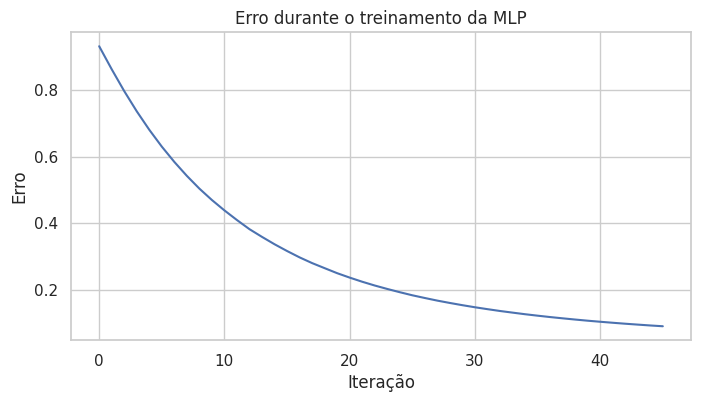

Erro final registrado: 0.0899


In [13]:
mlp = modelo_mlp.named_steps["mlp"]

plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_)
plt.title("Erro durante o treinamento da MLP")
plt.xlabel("Iteração")
plt.ylabel("Erro")
plt.show()

print(f"Erro final registrado: {mlp.loss_curve_[-1]:.4f}")


### 2.7. Avaliação na validação

Agora avaliaremos o modelo em dados que não participaram diretamente do ajuste dos pesos. A acurácia informa a proporção total de previsões corretas; precisão, recall e F1-score ajudam a examinar o desempenho por classe.

In [7]:
y_pred_validacao = modelo_mlp.predict(X_validacao)

print(f"Acurácia na validação: {accuracy_score(y_validacao, y_pred_validacao):.4f}")
print("\nRelatório de classificação:")
print(classification_report(
    y_validacao,
    y_pred_validacao,
    target_names=dados.target_names,
    zero_division=0
))


Acurácia na validação: 0.9670

Relatório de classificação:
              precision    recall  f1-score   support

   malignant       0.97      0.94      0.96        34
      benign       0.97      0.98      0.97        57

    accuracy                           0.97        91
   macro avg       0.97      0.96      0.96        91
weighted avg       0.97      0.97      0.97        91



### 2.8. Matriz de confusão

A matriz de confusão mostra como as amostras de cada classe foram classificadas. Verifique qual classe corresponde a cada linha e coluna e considere as consequências de falsos positivos e falsos negativos no contexto de apoio ao diagnóstico. Um modelo didático como este não deve ser utilizado para decisões clínicas.

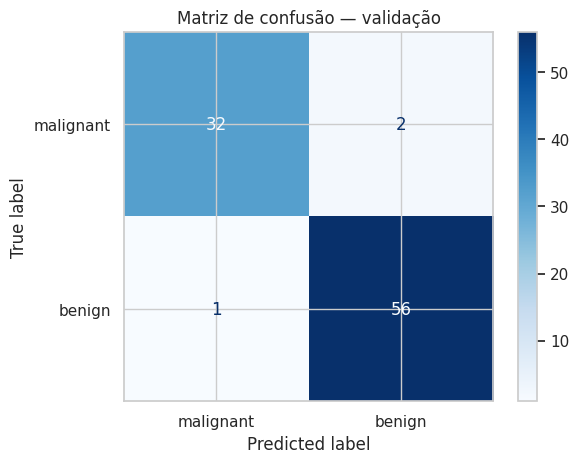

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_validacao,
    y_pred_validacao,
    display_labels=dados.target_names,
    cmap="Blues",
    values_format="d"
)
plt.title("Matriz de confusão — validação")
plt.show()


### 2.9. Comparação de arquiteturas

A arquitetura da rede é um hiperparâmetro. Vamos comparar duas configurações mantendo a mesma divisão dos dados e o mesmo pré-processamento. Não escolha apenas pela acurácia: observe também o F1-score e o tempo/custo de treinamento. A validação é apropriada para comparar modelos; o conjunto de teste continuará reservado.

In [9]:
configuracoes = {
    "MLP (16,)": (16,),
    "MLP (32, 16)": (32, 16),
    "MLP (64, 32)": (64, 32)
}

resultados = []

for nome, camadas in configuracoes.items():
    candidato = Pipeline([
        ("padronizacao", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=camadas,
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=RANDOM_STATE
        ))
    ])

    candidato.fit(X_treino, y_treino)
    pred = candidato.predict(X_validacao)
    relatorio = classification_report(
        y_validacao, pred, output_dict=True, zero_division=0
    )

    resultados.append({
        "arquitetura": nome,
        "acurácia": accuracy_score(y_validacao, pred),
        "F1 macro": relatorio["macro avg"]["f1-score"],
        "iterações": candidato.named_steps["mlp"].n_iter_
    })

comparacao = pd.DataFrame(resultados).sort_values("F1 macro", ascending=False)
display(comparacao.round(4))


,arquitetura,acurácia,F1 macro,iterações
1,"MLP (32, 16)",0.9670,0.9646,46
2,"MLP (64, 32)",0.9121,0.9005,31
0,"MLP (16,)",0.8571,0.8306,43


### 2.10. Avaliação final no conjunto de teste

Para concluir a prática, selecionaremos a arquitetura de melhor F1 macro na validação, treinaremos novamente com os conjuntos de treino e validação combinados e faremos uma única avaliação no teste. O conjunto de teste não deve ser usado repetidamente para escolher hiperparâmetros.

Arquitetura selecionada pela validação: MLP (32, 16)
Acurácia no teste: 0.9737

Relatório final no teste:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



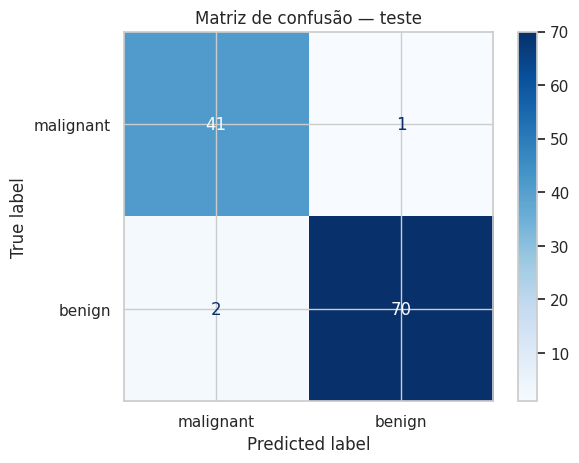

In [10]:
melhor_nome = comparacao.iloc[0]["arquitetura"]
melhor_camadas = configuracoes[melhor_nome]
print("Arquitetura selecionada pela validação:", melhor_nome)

X_treino_completo = pd.concat([X_treino, X_validacao], axis=0)
y_treino_completo = pd.concat([y_treino, y_validacao], axis=0)

modelo_final = Pipeline([
    ("padronizacao", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=melhor_camadas,
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=RANDOM_STATE
    ))
])

modelo_final.fit(X_treino_completo, y_treino_completo)
y_pred_teste = modelo_final.predict(X_teste)

print(f"Acurácia no teste: {accuracy_score(y_teste, y_pred_teste):.4f}")
print("\nRelatório final no teste:")
print(classification_report(
    y_teste, y_pred_teste,
    target_names=dados.target_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred_teste,
    display_labels=dados.target_names,
    cmap="Blues",
    values_format="d"
)
plt.title("Matriz de confusão — teste")
plt.show()


## Reflexão

Responda às questões abaixo individualmente. Utilize os resultados obtidos, as visualizações e os conceitos da teoria para justificar suas respostas. Não basta repetir a saída do código: explique o que ela significa.

1. **Arquitetura:** o que representam as configurações `(16,)`, `(32, 16)` e `(64, 32)`? Por que aumentar o número de neurônios não garante, necessariamente, melhor desempenho?
2. **Padronização:** por que a MLP pode ser afetada por atributos com escalas muito diferentes? O que o `Pipeline` garante em relação ao ajuste do `StandardScaler`?
3. **Aprendizado:** descreva, com suas palavras, o papel da propagação direta, da função de perda e do *backpropagation* durante o treinamento.
4. **Convergência:** o que você observa na curva de perda? Ela, sozinha, permite concluir que o modelo generaliza bem? Justifique.
5. **Métricas:** compare acurácia e F1 macro na validação. Por que é importante examinar métricas por classe em um problema como esse?
6. **Generalização:** compare o resultado de validação com o resultado final de teste. O que essa diferença sugere? Quais cuidados são necessários para não ajustar excessivamente o modelo ao conjunto de validação?
7. **Limitações:** cite duas limitações de uma MLP e explique por que os resultados desta prática não autorizam seu uso direto em decisões clínicas.


# 3. Prática Contextualizada

Agora, cada aluno deverá aplicar uma MLP a um **problema real ou tecnicamente plausível**, preferencialmente relacionado à Engenharia Biomédica, Engenharia de Produção ou a outra área de interesse. O objetivo é adaptar o raciocínio e o código da prática guiada, e não apenas trocar o nome do conjunto de dados.

## Orientações

- Defina um problema de **classificação ou regressão** e explique por que uma MLP pode ser adequada.
- Selecione um conjunto de dados acessível e informe a fonte, o significado das variáveis e a variável-alvo.
- Adapte o notebook: inspeção dos dados, divisão adequada, pré-processamento, definição da arquitetura, treinamento e avaliação.
- Compare pelo menos **duas configurações** ou justifique uma escolha de arquitetura com base em evidências.
- Apresente métricas adequadas ao problema e interprete os erros mais relevantes.
- Discuta limitações, possíveis vieses, risco de sobreajuste e o que seria necessário para utilizar a solução em um cenário real.
- Registre as fontes consultadas e declare de forma específica qualquer uso de ferramenta de IA generativa, indicando em que parte ela foi utilizada. O aluno deve compreender e justificar todo o trabalho apresentado.

## Apresentação

A pessoa selecionada apresentará o trabalho na próxima aula. A apresentação deverá ser breve e técnica, mostrando o problema, os dados, as principais decisões de implementação, os resultados e suas limitações. A turma poderá fazer perguntas e oferecer feedback; o apresentador deverá justificar as escolhas com base no código e nas evidências observadas.

**Entrega sugerida:** notebook executável no Google Colab, com as saídas preservadas, fonte do conjunto de dados e respostas às questões de reflexão.
